# What is in the randoms that fail the quiet-noise cut? Series 07221203_2025, dump F0001

The noise notebook (`noise-psd-randoms-buddy.ipynb`) keeps only the randoms that pass the quiet-noise cut (Tight excursion band and `log10(bstd) < 0.5`) in every working channel: 31 of the 1008 randoms. The other 977 are thrown away, and the cut rejects them for a reason. This notebook looks at them: **when one board or another fails the cut, what is in the traces?**

Questions, in order:

1. Which boards fail together? Do the DCRC1 channels, the DCRC3 channels and DCRC4's one working channel fail on the same events, or independently? (section 2)
2. Which part of the cut rejects them, the excursion band or the baseline scatter? (section 3)
3. What does an event look like in all the working channels at once, for each failure pattern? (section 4)
4. Where in the trace is the excursion, and how big is it? (section 5)

It uses the shared `python/` library, including `pulse_channels` for the channel names (provisional, see section 7 of the noise notebook). The cut is applied to each channel's own trace, as in the noise notebook. Run with the `darkmatter_cli_env` kernel.

**Caveat carried over from Note 2a.** `pulse_cuts.randoms` assumes the dump's trigger-type labels are swapped (events recorded as `Physics` are taken to be randoms). This is a working assumption, not confirmed.

*Author: buddy. Draft.*

In [1]:
import sys
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))

import collections
import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_quantities as pq
import pulse_operations as po
import pulse_cuts as pc
import pulse_channels as pch

def short_label(det, ch):
    """Channel name with its readout board, e.g. 'Side2pC (DCRC1)'."""
    return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
from pulse_config import PulseConfig

import check_environment
check_environment.check()

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


[]

## 1. Load the dump and measure every channel

For each of the 12 channels the cell below computes, for every event, the quantities the cut is built from: the baseline scatter `bstd`, the largest excursion after the pretrigger window `dev`, their ratio, and the sample where that largest excursion happens. Only these numbers are kept, not the traces (those are reloaded in section 4 when they are plotted).

In [2]:
DUMP = "07221203_2025_F0001"
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10, sample_period_s=1.6e-6)
cdms = load_all_data(str(Path.home() / "idx" / DUMP))
det_ids = {det: pio.filter_by_detector(cdms.get_detector_ids(), det) for det in range(3)}

# The three boards share their events, in the same order, so one event list serves every channel.
event_numbers = np.array([int(pio.event_id(i)) for i in det_ids[0]])
is_random = pc.randoms(pio.trigger_types(cdms, det_ids[0]))
for det in (1, 2):
    assert np.array_equal(event_numbers, [int(pio.event_id(i)) for i in det_ids[det]])
    assert np.array_equal(is_random, pc.randoms(pio.trigger_types(cdms, det_ids[det])))

q = {}   # (detector, channel) -> arrays with one entry per event
for det in range(3):
    for ch in range(4):
        _, p = pio.load_channel_batch(cdms, det_ids[det], ch)
        with np.errstate(all="ignore"):          # a constant (dead) channel has zero baseline scatter
            bstd = pq.bstd(p, config_500)
            dev = pq.max_deviation(p, config_500)
            ratio = pq.excursion_ratio(p, config_500)
            band = pc.excursion_band(p, config_500)
            scatter_ok = np.log10(bstd) < 0.5
        after = np.abs(p[:, config_500.pretrigger_samples:] - pq.pretrigger_mean(p, config_500)[:, None])
        q[(det, ch)] = dict(bstd=bstd, dev=dev, ratio=ratio, band=band, scatter_ok=scatter_ok,
                            quiet=band & scatter_ok, argmax=config_500.pretrigger_samples + after.argmax(axis=1))

# A channel is working if its own cut keeps at least 2 randoms; the others read a constant and can never pass
working = [k for k in q if (q[k]["quiet"] & is_random).sum() >= 2]
board_of = {k: pch.channel_info(*k).dcrc for k in working}
print(f"{len(event_numbers)} events, {is_random.sum()} randoms; working channels:")
for k in working:
    print(f"  {short_label(*k):<28} passes the cut for {(q[k]['quiet'] & is_random).sum():>4} randoms")

C:\Users\villanoa\AppData\Local\Temp\ipykernel_26080\2580600802.py:8: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  is_random = pc.randoms(pio.trigger_types(cdms, det_ids[0]))
C:\Users\villanoa\AppData\Local\Temp\ipykernel_26080\2580600802.py:11: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  assert np.array_equal(is_

1517 events, 1008 randoms; working channels:
  Side2pC (DCRC1)              passes the cut for  141 randoms
  Side2pF (DCRC1)              passes the cut for  107 randoms
  Side1pF (DCRC1)              passes the cut for  109 randoms
  Side1pE (DCRC3)              passes the cut for  161 randoms
  Side1pB (DCRC3)              passes the cut for  101 randoms
  Side2pE (DCRC3)              passes the cut for  180 randoms
  Side2pB (DCRC4)              passes the cut for  958 randoms


C:\Users\villanoa\AppData\Local\Temp\ipykernel_26080\2580600802.py:29: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  board_of = {k: pch.channel_info(*k).dcrc for k in working}
C:\Users\villanoa\AppData\Local\Temp\ipykernel_26080\4104789735.py:22: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\Research\NSDF-Data\python\pulse_channels.py:83: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not

## 2. Which boards fail together?

For each random, the **failure pattern** is the set of boards that have at least one working channel failing the cut on that event. If the failures were independent between boards, the patterns "DCRC1 only" and "DCRC3 only" would be common. If they come from something that hits every channel (a real pulse seen by all the boards, or a pickup), "DCRC1+DCRC3" would dominate.

failure pattern (boards with a failing channel)    randoms
DCRC1 + DCRC3                                          865
DCRC1 + DCRC3 + DCRC4                                   43
DCRC1                                                   41
passes everywhere                                       31
DCRC3                                                   21
DCRC4                                                    3
DCRC3 + DCRC4                                            3
DCRC1 + DCRC4                                            1


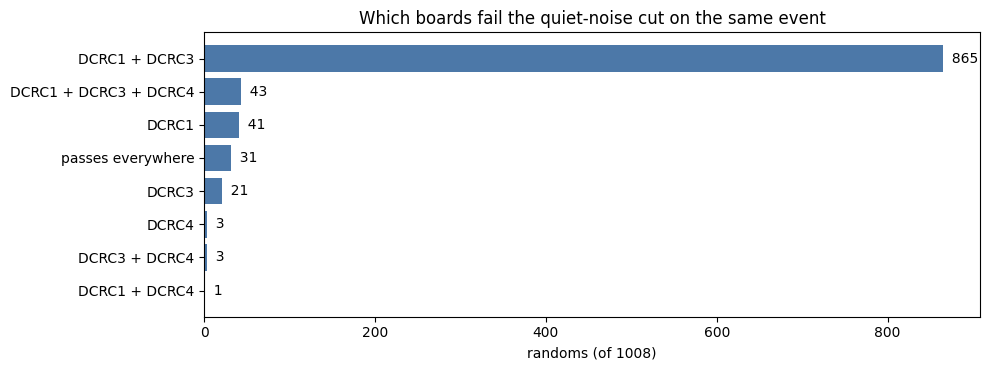

In [3]:
fails = np.array([~q[k]["quiet"] for k in working])           # (working channels, events)
def pattern(e):
    boards = sorted({board_of[k] for k, f in zip(working, fails[:, e]) if f})
    return " + ".join(boards) if boards else "passes everywhere"
patterns = np.array([pattern(e) for e in range(len(event_numbers))], dtype=object)

counts = collections.Counter(patterns[is_random])
print(f"{'failure pattern (boards with a failing channel)':<50}{'randoms':>8}")
for pat, n in counts.most_common():
    print(f"{pat:<50}{n:>8}")

fig, ax = plt.subplots(figsize=(10, 3.8))
labels, values = zip(*counts.most_common())
ax.barh(range(len(labels))[::-1], values, color="#4c78a8")
ax.set_yticks(range(len(labels))[::-1]); ax.set_yticklabels(labels)
for y, v in zip(range(len(labels))[::-1], values):
    ax.text(v, y, f"  {v}", va="center")
ax.set_xlabel(f"randoms (of {is_random.sum()})")
ax.set_title("Which boards fail the quiet-noise cut on the same event")
fig.tight_layout()
plt.savefig(f"figures/failure-patterns-{DUMP}.png", dpi=110)
plt.show()

## 3. Which part of the cut rejects them?

For each working channel, among the randoms that fail the cut: how many fail only the excursion band, only the baseline scatter (`log10(bstd) < 0.5`), or both. The Tight band is a window, so a trace can fall outside it on either side: an excursion that is too large (a pulse or a step) or too small (a trace that is quieter than the band expects).

In [4]:
print(f"{'channel':<28}{'fail':>6}{'band only':>11}{'scatter only':>14}{'both':>7}   band: too big / too small")
for k in working:
    d = q[k]; r = is_random & ~d["quiet"]
    band_only = (r & ~d["band"] & d["scatter_ok"]).sum()
    scatter_only = (r & d["band"] & ~d["scatter_ok"]).sum()
    both = (r & ~d["band"] & ~d["scatter_ok"]).sum()
    with np.errstate(all="ignore"):
        lr = np.log10(d["ratio"])
    too_big = (r & ~d["band"] & (lr >= 0.7)).sum()
    too_small = (r & ~d["band"] & (lr < 0.5)).sum()
    print(f"{short_label(*k):<28}{r.sum():>6}{band_only:>11}{scatter_only:>14}{both:>7}   {too_big:>5} / {too_small:<5}")

channel                       fail  band only  scatter only   both   band: too big / too small
Side2pC (DCRC1)                867        754             9    104     831 / 27   
Side2pF (DCRC1)                901        738            10    153     858 / 33   
Side1pF (DCRC1)                899        760             7    132     863 / 29   
Side1pE (DCRC3)                847        609            15    223     799 / 33   
Side1pB (DCRC3)                907        674            25    208     848 / 34   
Side2pE (DCRC3)                828        597             9    222     782 / 37   
Side2pB (DCRC4)                 50         50             0      0      12 / 38   


C:\Users\villanoa\AppData\Local\Temp\ipykernel_26080\4104789735.py:22: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\Research\NSDF-Data\python\pulse_channels.py:83: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return channel_info(detector, channel).name
C:\Users\villanoa\AppData\Local\Temp\ipykernel_26080\4104789735.py:22: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed 

## 4. What an event looks like in every working channel

One column per failure pattern, one row per working channel, for one randomly chosen event of each pattern (seeded). The traces are baseline-subtracted (500-sample window) with the leading glitch samples skipped. The dot marks the sample of the largest excursion after the pretrigger window. The event numbers are in the column titles.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_26080\2865613479.py:14: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  ax.plot(x, trace[glitch:], linewidth=0.6, color="#d95f02" if pch.channel_info(*k).side == 2 else "#1f77b4")
C:\Users\villanoa\AppData\Local\Temp\ipykernel_26080\2865613479.py:20: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  ax.set_ylabel(pch.channel_info(*k).name, fontsize=10)


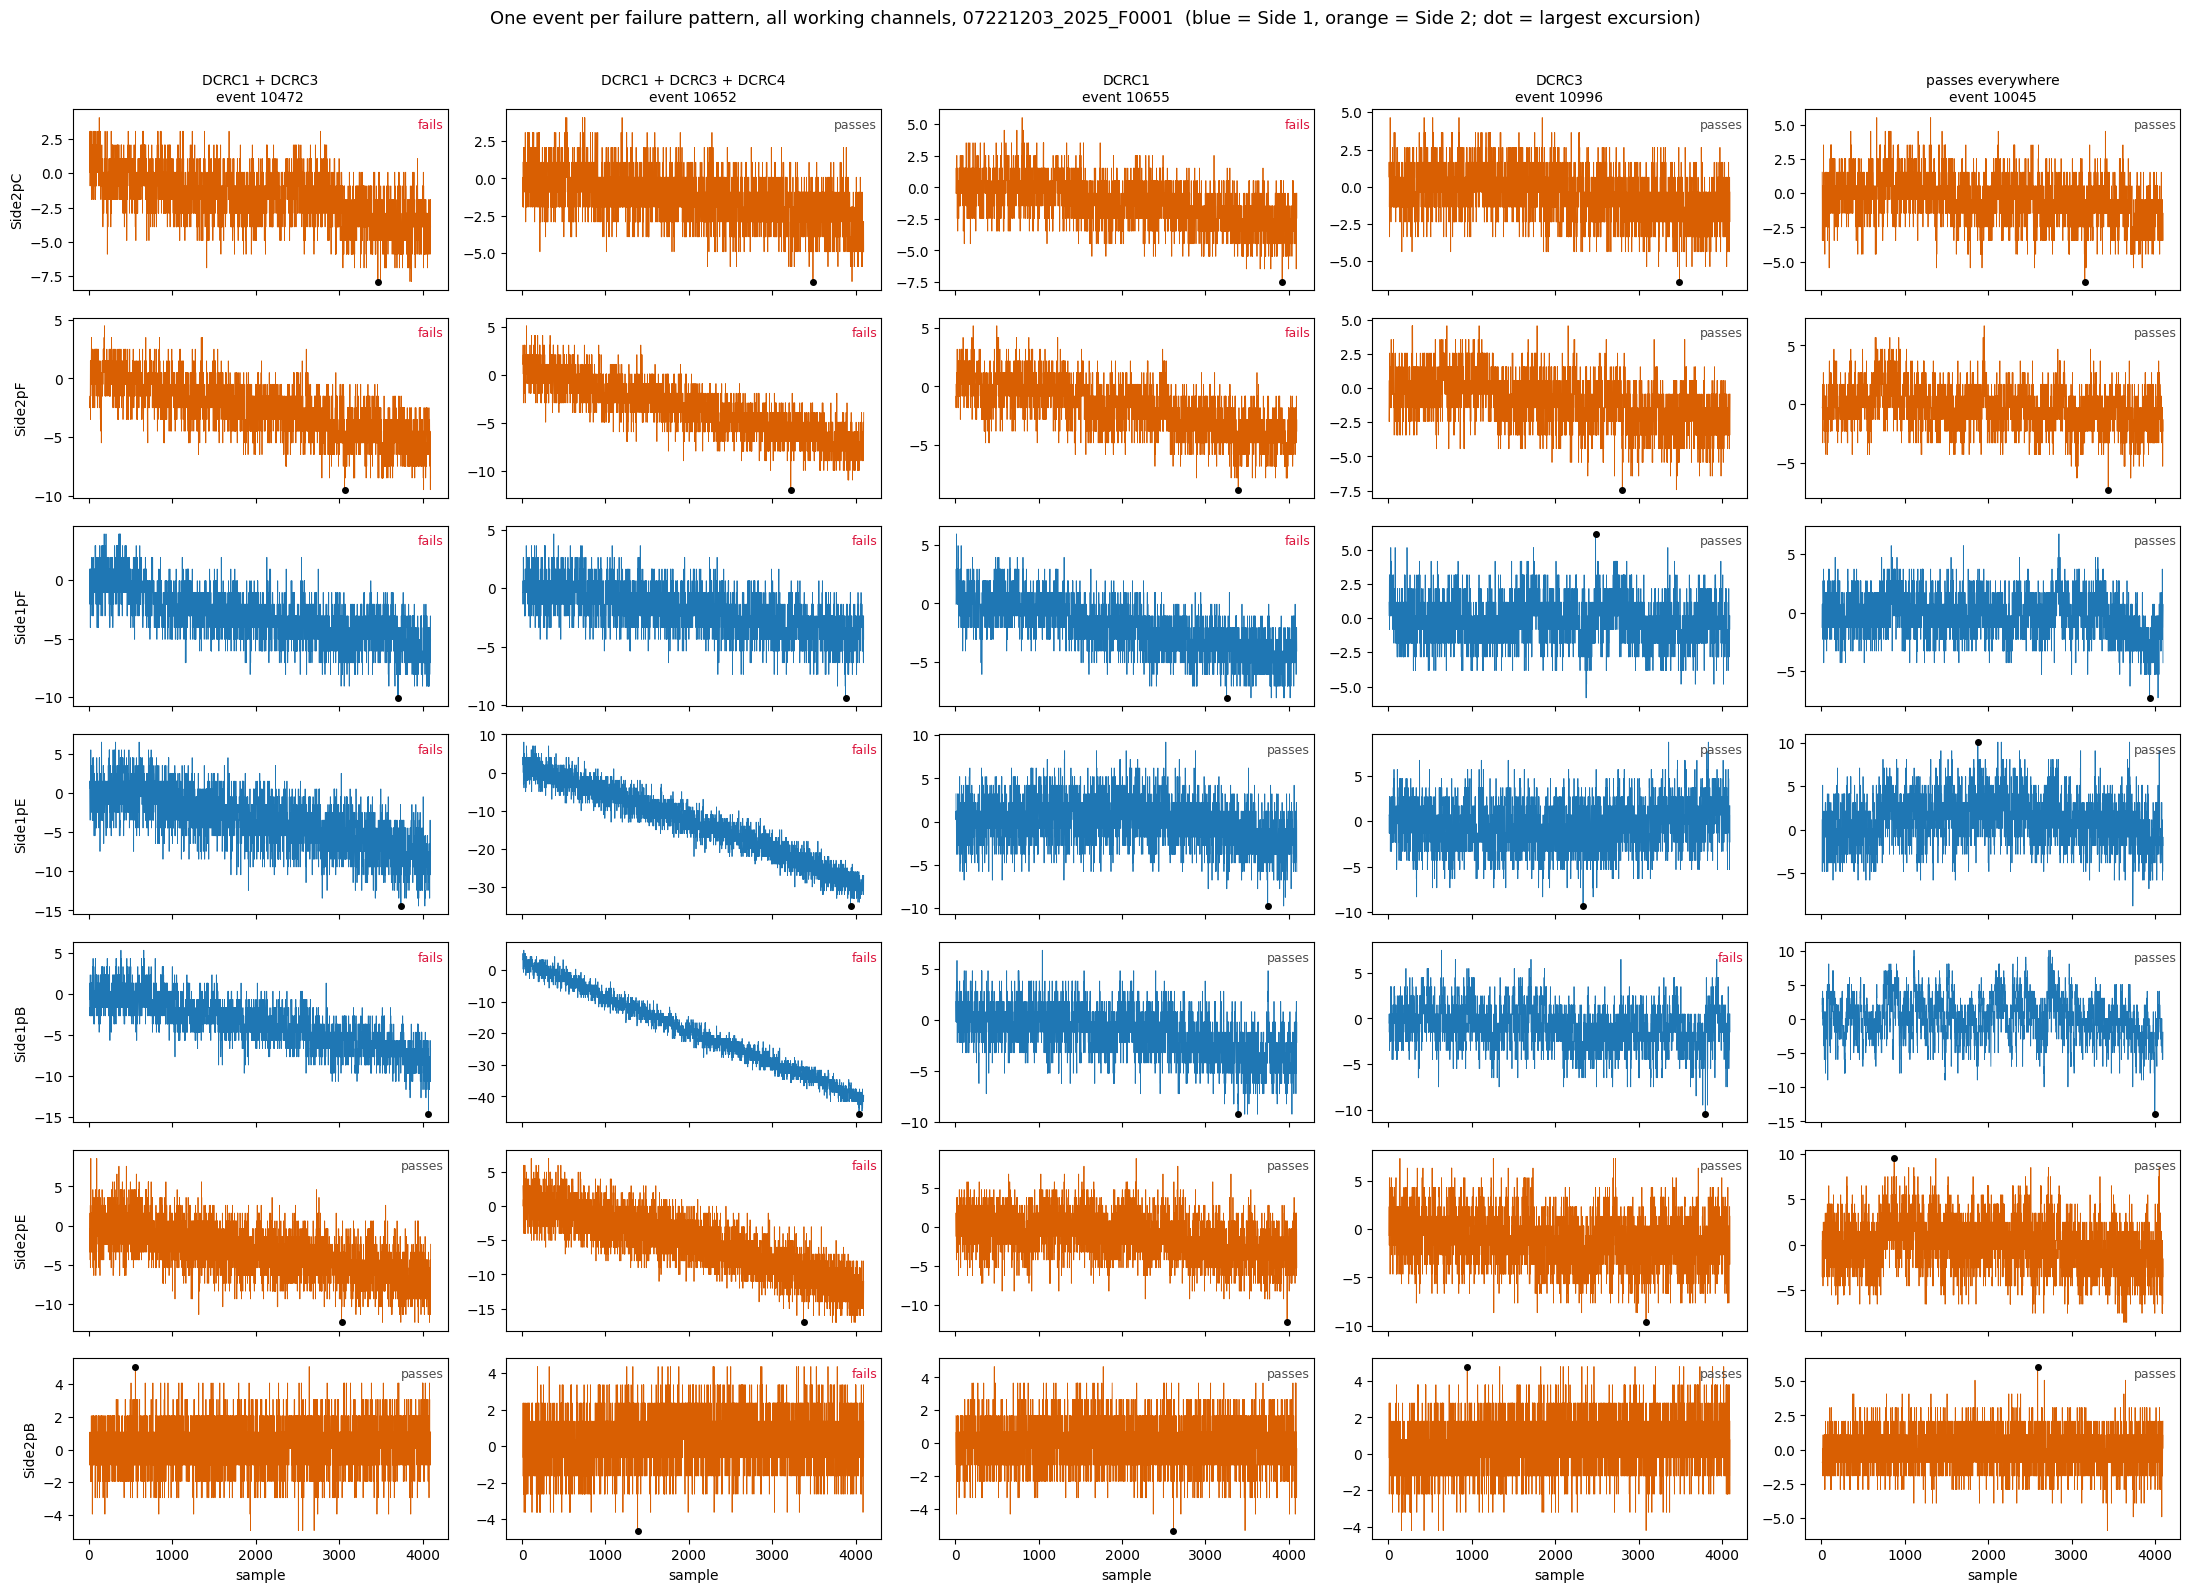

In [5]:
rng = np.random.default_rng(1)
shown_patterns = [pat for pat, _ in counts.most_common() if pat != "passes everywhere"][:4] + ["passes everywhere"]
chosen = {pat: int(rng.choice(np.flatnonzero(is_random & (patterns == pat)))) for pat in shown_patterns}

batch = {k: pio.load_channel_batch(cdms, det_ids[k[0]], k[1])[1] for k in working}   # the traces of the working channels
glitch = config_500.glitch_samples
x = np.arange(glitch, 4096)
fig, axes = plt.subplots(len(working), len(shown_patterns), figsize=(22, 2.1 * len(working) + 1.5), sharex=True)
for j, pat in enumerate(shown_patterns):
    e = chosen[pat]
    for i, k in enumerate(working):
        ax = axes[i, j]
        trace = batch[k][e] - pq.bline(batch[k][e:e + 1], config_500)[0]
        ax.plot(x, trace[glitch:], linewidth=0.6, color="#d95f02" if pch.channel_info(*k).side == 2 else "#1f77b4")
        ax.plot(q[k]["argmax"][e], trace[q[k]["argmax"][e]], "o", color="k", markersize=4)
        failed = not q[k]["quiet"][e]
        ax.text(0.99, 0.95, "fails" if failed else "passes", transform=ax.transAxes, ha="right", va="top",
                fontsize=9, color="crimson" if failed else "0.3")
        if j == 0:
            ax.set_ylabel(pch.channel_info(*k).name, fontsize=10)
        if i == 0:
            ax.set_title(f"{pat}\nevent {event_numbers[e]}", fontsize=10)
        if i == len(working) - 1:
            ax.set_xlabel("sample")
fig.suptitle(f"One event per failure pattern, all working channels, {DUMP}  (blue = Side 1, orange = Side 2; dot = largest excursion)", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig(f"figures/failure-events-{DUMP}.png", dpi=100)
plt.show()

## 5. Where is the excursion, and how big?

For the randoms that fail, the sample of the largest excursion after the pretrigger window (0 to 4095, the pretrigger window is the first 500) and its size in units of the baseline scatter (`ratio`), one line per failure pattern, using one working channel per board: the first working channel of DCRC1, DCRC3 and DCRC4. An excursion at the start of the post-pretrigger window, shrinking with time, is a tail of an earlier pulse; one in the middle is a pulse that arrived during the trace.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_26080\4104789735.py:22: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_26080\4104789735.py:22: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"


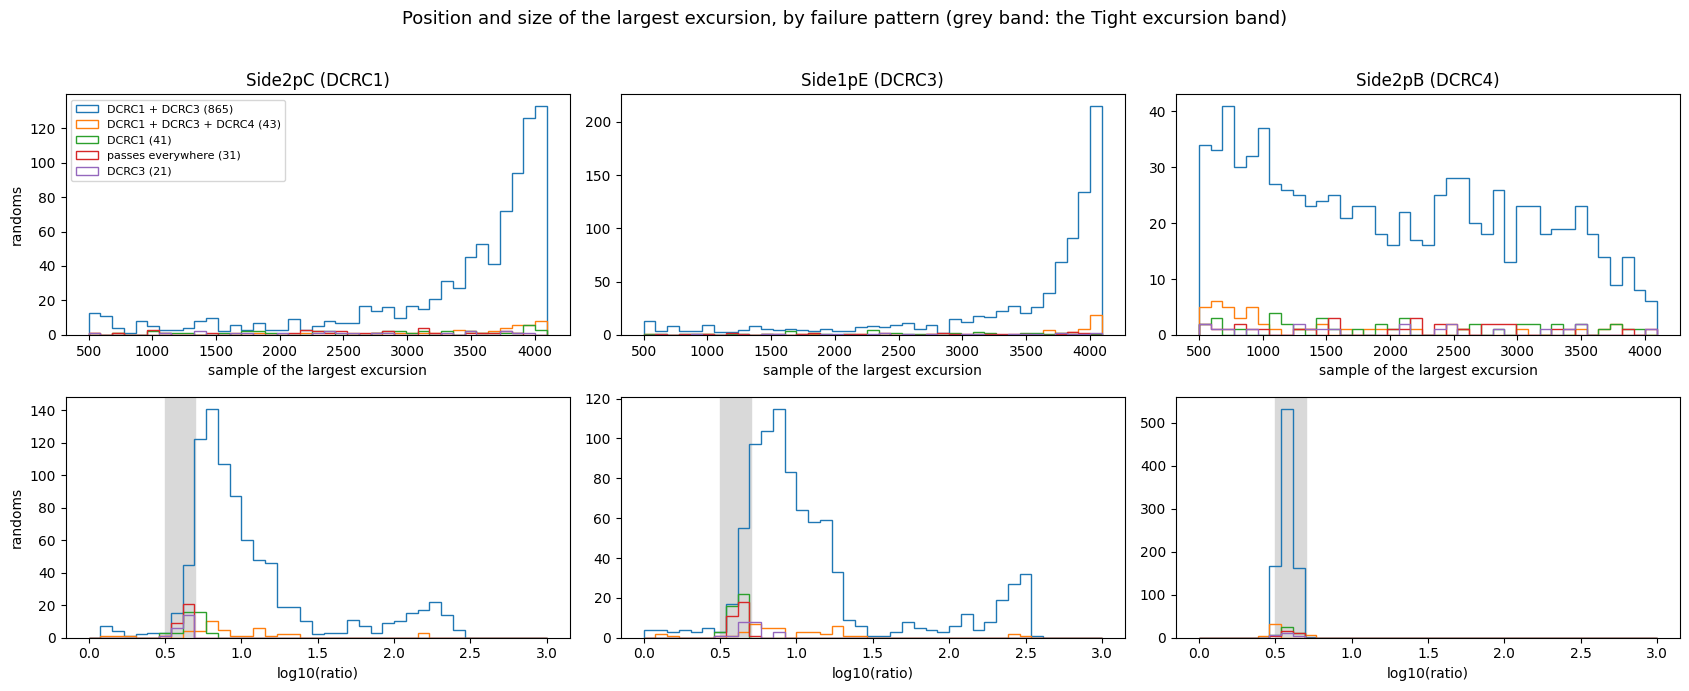

In [6]:
first_of_board = {}
for k in working:
    first_of_board.setdefault(board_of[k], k)
fig, axes = plt.subplots(2, len(first_of_board), figsize=(17, 7))
bins_x = np.linspace(config_500.pretrigger_samples, 4096, 40)
bins_r = np.linspace(0, 3, 40)
for j, (board, k) in enumerate(first_of_board.items()):
    for pat in [p for p, _ in counts.most_common()][:5]:
        sel = is_random & (patterns == pat)
        with np.errstate(all="ignore"):
            axes[0, j].hist(q[k]["argmax"][sel], bins=bins_x, histtype="step", label=f"{pat} ({sel.sum()})")
            axes[1, j].hist(np.log10(q[k]["ratio"][sel]), bins=bins_r, histtype="step")
    axes[0, j].set_title(f"{short_label(*k)}")
    axes[0, j].set_xlabel("sample of the largest excursion"); axes[1, j].set_xlabel("log10(ratio)")
    axes[1, j].axvspan(0.5, 0.7, color="0.85", zorder=0)    # the Tight band
axes[0, 0].legend(fontsize=8); axes[0, 0].set_ylabel("randoms"); axes[1, 0].set_ylabel("randoms")
fig.suptitle("Position and size of the largest excursion, by failure pattern (grey band: the Tight excursion band)", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.savefig(f"figures/failure-excursions-{DUMP}.png", dpi=110)
plt.show()

## 6. What the failures are (this dump only)

- **The boards fail together.** Of the 1008 randoms, 865 fail on both DCRC1 and DCRC3, 43 fail on all three boards, 41 on DCRC1 only, 21 on DCRC3 only, and 31 pass everywhere. Failing on one board and not the other is rare, so the cut is not catching independent problems in single channels: something common to the DCRC1 and DCRC3 channels is rejecting the same events.
- **It is the excursion band, and nearly always on the high side.** On the six DCRC1 and DCRC3 channels most failures fail only the Tight band (597 to 760 of 828 to 907), and about 96% of the band failures are *too big* (`log10(ratio) >= 0.7`). The baseline-scatter condition alone rejects only 7 to 25 per channel.
- **For most failures, the largest excursion is at the end of the trace.** For most failures on DCRC1 and DCRC3 it falls between about sample 3500 and 4095 (section 5), and the event displays (section 4) show why: these traces are noise on a **slow downward baseline drift**, a ramp of roughly 5 to 15 counts across the trace in the typical failing event, and 30 to 40 counts in the steepest one shown (event 10652, in the DCRC3 channels). The last samples are then far from the pretrigger mean, so `dev` and the ratio come out large. These are not pulses.
- **Most failures are just above the band.** Their `log10(ratio)` is mostly 0.7 to 1.4, next to the Tight band's upper edge of 0.7. A second, smaller group sits at 2.0 to 2.5 (ratio 100 to 300): these are real pulses, steps of tens to hundreds of counts with a slow recovery, which about 27% of the randoms contain in at least one DCRC1 or DCRC3 channel (see `baseline-drift-buddy.ipynb`). The ramp description above applies to the rest.
- **DCRC4's `Side2pB` is different.** Its largest excursion is spread evenly along the trace and almost all of its randoms sit inside the band; the few that fail, fail on one side or the other of the band.

**What it means for the noise notebook.** The quiet-noise cut selects on the baseline slope as much as on the noise: the 31 events it keeps are the ones with the least drift, and even those still sag by a count or two. A ramp has a spectrum that falls steeply with frequency, so some of the low-frequency rise in the noise PSD is probably this drift and not noise. Removing a straight-line fit (or the trace mean and slope) before the FFT, and comparing the PSD with and without it, would show how much.

## Next steps

- Compare the noise PSD of the globally cut traces with and without a straight-line fit removed before the FFT, to see how much of the low-frequency rise is the baseline drift (noise notebook).
- The second group of failures (`log10(ratio)` from 2 to 2.5) is real pulses; the pulse and ramp populations are separated in `baseline-drift-buddy.ipynb`, which also asks whether one channel ever ramps alone.
- Measure the drift directly (slope of a line fitted to each trace) and see whether it is the same on every channel of an event and correlated with the event time.
- Decide whether the Tight band should be replaced by a cut on the detrended trace, or loosened (`excursion_band_loose` keeps 383 events globally).
- Repeat with the other dumps of the series (F0002 to F0005) with `pio.load_channel_batch_multi`.